# NeuroScan — Phase 2, Track 2: EfficientNetB0 transfer learning (the main model)

**Owner:** Laiba Amjad (23L-0642) · **Course:** DataScience, FAST-NUCES Lahore

## What this notebook does

Track 1 gave us a from-scratch CNN (accuracy 0.806) and a first EfficientNetB0 (accuracy 0.855). That EfficientNet
was the *phase-A checkpoint* only: fine-tuning had broken it, because unfreezing the base switched every
BatchNorm layer into training mode (validation accuracy fell from 0.9355 to 0.7584 in one epoch).
Track 2 is the main model, so the job is to **make fine-tuning work and to choose the settings with evidence**.

| Step | What | Why |
|---|---|---|
| 1 | Load the shared Phase 1 pipeline | Same split, seed, augmentation and metrics as every other track, so the numbers are comparable |
| 2 | Build EfficientNetB0 with BatchNorm kept frozen | The fix for Track 1's known issue |
| 3 | **Experiment 1** — head training: learning rate × dropout | Hyperparameter tuning, stage 1 |
| 4 | **Experiment 2** — fine-tuning: unfreeze depth × fine-tuning learning rate | Hyperparameter tuning, stage 2 |
| 5 | **Experiment 3** — augmentation ablation | `data.py` flags horizontal flip as questionable for brain MRI |
| 6 | Pick the final configuration **using validation data only** | The test set must not influence model selection |
| 7 | Retrain the winner with 3 seeds, then evaluate on the test set | Shows whether differences are real or seed noise |
| 8 | Error analysis and comparison with Track 1 | Where does it fail, and is it better than the baselines? |

### Rules this notebook follows (from `PHASE2.md`)
* Data comes only from `neuroscan/data.py`, scoring only from `neuroscan/evaluate.py`. The split is Phase 1's and is never re-rolled.
* `preprocess="efficientnet"` (inputs stay 0–255, because the model normalises internally) — this avoids double normalisation.
* Selection uses the **validation** split. The test split is touched only for the final reporting.
* The leaky pipeline is not used anywhere in this notebook.

## 0. Setup

Run this on **Google Colab with a GPU** (Runtime → Change runtime type → T4 GPU). On a laptop CPU the full run would take many hours.
It saves its progress to Google Drive and can be resumed after a disconnect (see *Saving progress and resuming* below). The next cell clones the repository on Colab; on a local machine it does nothing (start Jupyter from the repo root).

In [1]:
# Colab: clone the repo (on the Track 2 branch). Local: this cell is a no-op.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
REPO   = "NeuroScan"
BRANCH = "main"                # the branch this notebook lives on

if IN_COLAB and not os.path.isdir(REPO):
    subprocess.run(["git", "clone", "--branch", BRANCH,
                    "https://github.com/laibaamjad50/NeuroScan.git"], check=True)
if IN_COLAB:
    os.chdir(REPO)

print("working directory:", os.getcwd())
assert os.path.isdir("neuroscan"), "run this from the repository root"

working directory: /content/NeuroScan


In [2]:
!pip install -q -r requirements-phase2.txt

In [3]:
# processed_data/ is gitignored (about 300 MB). Rebuild it from the manifest; files already on disk are skipped.
!python scripts/build_processed_data.py

manifest rows     : 6,762
already on disk   : 6,762
to build          : 0
Preprocessing: 100% 6762/6762 [00:00<00:00, 69228.34it/s]

built 0 | skipped 6,762 | failed 0
processed_data/ now holds 6,762 of 6,762 expected images


### Configuration

All the knobs are in one place. Set `QUICK = True` for a one-epoch smoke test of the *whole notebook* (a few minutes; the
numbers it produces are meaningless). Set it back to `False` for the real run.

In [4]:
import gc, json, os, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

sys.path.insert(0, os.getcwd())
from neuroscan import data, evaluate

# ---------------------------------------------------------------- configuration
QUICK   = False          # True = tiny smoke test, results meaningless
SEED    = 42             # the project-wide seed (PHASE2.md)
WEIGHTS = "imagenet"     # pre-trained weights for the backbone

EP_HEAD = 1 if QUICK else 15      # max epochs, head training (early stopping usually ends it sooner)
EP_FT   = 1 if QUICK else 12      # max epochs, fine-tuning
PATIENCE = 4                      # early-stopping patience on val_loss

# Experiment 1: head training grid (the backbone is frozen)
HEAD_GRID = [dict(lr_head=lr, dropout=do) for lr in (1e-3, 3e-4) for do in (0.3, 0.5)]
# Experiment 2: fine-tuning grid, run from the best head model of Experiment 1
FT_GRID   = [dict(ft_layers=n, lr_ft=lr) for n in (20, 50, 100) for lr in (1e-5, 3e-5)]
# Final retraining seeds (variance estimate)
FINAL_SEEDS = [42] if QUICK else [42, 7, 123]
if QUICK:
    HEAD_GRID, FT_GRID = HEAD_GRID[:2], FT_GRID[:2]

os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)
keras.utils.set_random_seed(SEED)

print("TensorFlow", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "NONE - this will be very slow")

report = data.verify(full=True)
print("\nPhase 1 outputs:", "OK" if report["ok"] else "PROBLEM", "|", report["counts"])
for p in report["problems"]:
    print("  -", p)
assert report["ok"], "fix the Phase 1 outputs before training"
CLASSES = report["classes"]
print("classes:", CLASSES)

TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Phase 1 outputs: OK | {'train': 4156, 'val': 1039, 'test': 1567}
classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


### Saving progress and resuming (Google Drive)

Colab sessions disconnect. So that no finished work is ever lost, this notebook **saves its progress to Google Drive** and **skips whatever is
already done** when you run it again:

| What | Saved | On re-run |
|---|---|---|
| Each finished experiment run (scores, settings) | right after the run | skipped |
| Each head model's weights (needed by Experiment 2) | right after the run | loaded, not retrained |
| A run that was interrupted part-way | after **every epoch** | continues from the last finished epoch |
| Each final seed (model weights + training curves) | right after the seed | loaded, not retrained |
| `results/track2_*`, `results/effnet_tuned_*`, `models/effnet_tuned.keras` | after every experiment | restored into the repo |

**To resume after a disconnect:** reopen the notebook and choose *Runtime → Run all*. The setup cells re-install the packages and rebuild `processed_data/`
(a few minutes, because it is a new machine), and then every finished run prints `[skip]`.

Progress lives in `My Drive/NeuroScan_Phase2_Track2/`. Set `RESET = True` below to delete it and start from scratch, which you should do if
you change the epochs or the grids. (`QUICK = True` uses a separate `_QUICK` folder, so a smoke test never contaminates the real run.)

In [5]:
import pickle, shutil

RESET = False      # True = delete all saved progress and start every experiment from scratch

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR = "/content/drive/MyDrive/NeuroScan_Phase2_Track2"
else:
    DRIVE_DIR = os.path.abspath("track2_cache")     # local runs: keep this folder out of git
DRIVE_DIR += "_QUICK" if QUICK else ""
CACHE, BACKUP = os.path.join(DRIVE_DIR, "cache"), os.path.join(DRIVE_DIR, "backup")

if RESET and os.path.isdir(DRIVE_DIR):
    shutil.rmtree(DRIVE_DIR); print("saved progress deleted")
os.makedirs(CACHE, exist_ok=True); os.makedirs(BACKUP, exist_ok=True)

def _atomic(path, writer, mode):
    tmp = path + ".tmp"                     # write to a temp file, then rename: a crash cannot leave a half-written file
    with open(tmp, mode) as fh: writer(fh)
    os.replace(tmp, path)

def save_json(name, obj):
    _atomic(os.path.join(CACHE, name + ".json"),
            lambda f: json.dump(obj, f, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o)), "w")

def load_json(name, default=None):
    p = os.path.join(CACHE, name + ".json")
    return json.load(open(p)) if os.path.exists(p) else default

def save_pickle(name, obj):
    _atomic(os.path.join(CACHE, name + ".pkl"), lambda f: pickle.dump(obj, f, protocol=4), "wb")

def load_pickle(name, default=None):
    p = os.path.join(CACHE, name + ".pkl")
    return pickle.load(open(p, "rb")) if os.path.exists(p) else default

MINE = ("track2_", "effnet_tuned_")         # only our own result files are synced; Track 1's files are never touched
def sync_to_drive():
    os.makedirs(f"{DRIVE_DIR}/results", exist_ok=True)
    for f in os.listdir("results"):
        if f.startswith(MINE):
            shutil.copy(f"results/{f}", f"{DRIVE_DIR}/results/{f}")
    if os.path.exists("models/effnet_tuned.keras"):
        shutil.copy("models/effnet_tuned.keras", f"{DRIVE_DIR}/effnet_tuned.keras")

def restore_from_drive():
    n = 0
    if os.path.isdir(f"{DRIVE_DIR}/results"):
        for f in os.listdir(f"{DRIVE_DIR}/results"):
            if f.startswith(MINE):
                shutil.copy(f"{DRIVE_DIR}/results/{f}", f"results/{f}"); n += 1
    if os.path.exists(f"{DRIVE_DIR}/effnet_tuned.keras"):
        shutil.copy(f"{DRIVE_DIR}/effnet_tuned.keras", "models/effnet_tuned.keras"); n += 1
    return n

print("progress folder:", DRIVE_DIR)
print("restored", restore_from_drive(), "result file(s) from a previous session")
print("finished runs found:", [r["name"] for r in load_json("all_runs", [])] or "none (fresh start)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
progress folder: /content/drive/MyDrive/NeuroScan_Phase2_Track2
restored 12 result file(s) from a previous session
finished runs found: ['head_lr0.001_do0.3', 'head_lr0.001_do0.5', 'head_lr0.0003_do0.3', 'head_lr0.0003_do0.5', 'ft_head_lr0.001_do0.3_top20_lr1e-05', 'ft_head_lr0.001_do0.3_top20_lr3e-05', 'ft_head_lr0.001_do0.3_top50_lr1e-05', 'ft_head_lr0.001_do0.3_top50_lr3e-05', 'ft_head_lr0.001_do0.3_top100_lr1e-05', 'ft_head_lr0.001_do0.3_top100_lr3e-05', 'head_lr0.001_do0.3_NOAUG']


## 1. Data

We use the shared clean pipeline with the EfficientNet settings: 3 channels (the greyscale PNGs are repeated across RGB for the
ImageNet backbone), pixel values left at 0–255, augmentation on the training split only.

The class weights are the mild Phase 1 weights. Because Keras requires the weights as a dict keyed by integer label, `data.py`
already does that for us.

In [6]:
BATCH = 32
def make_ds(seed=SEED, augment=True):
    return data.make_datasets(data.DataConfig(preprocess="efficientnet", channels=3,
                                              batch_size=BATCH, seed=seed, augment=augment))

ds = make_ds()
info = ds["info"]
CLASS_WEIGHTS = info["class_weights"]

print("split sizes  :", info["counts"])
print("input shape  :", info["input_shape"])
print("class weights:", {CLASSES[k]: round(v, 3) for k, v in CLASS_WEIGHTS.items()})

x, y = next(iter(ds["train"]))
print("batch pixel range:", float(tf.reduce_min(x)), "to", float(tf.reduce_max(x)),
      "(expected about 0-255: the model normalises internally)")

split sizes  : {'train': 4156, 'val': 1039, 'test': 1567}
input shape  : (224, 224, 3)
class weights: {'glioma': 0.93, 'meningioma': 1.009, 'notumor': 1.126, 'pituitary': 0.957}
batch pixel range: 0.0 to 255.0 (expected about 0-255: the model normalises internally)


**Sanity check — what does the model actually see?** A few augmented training images. If these look broken (all black, wrong
orientation, over-zoomed) the whole run would be wasted, so it is worth one look.

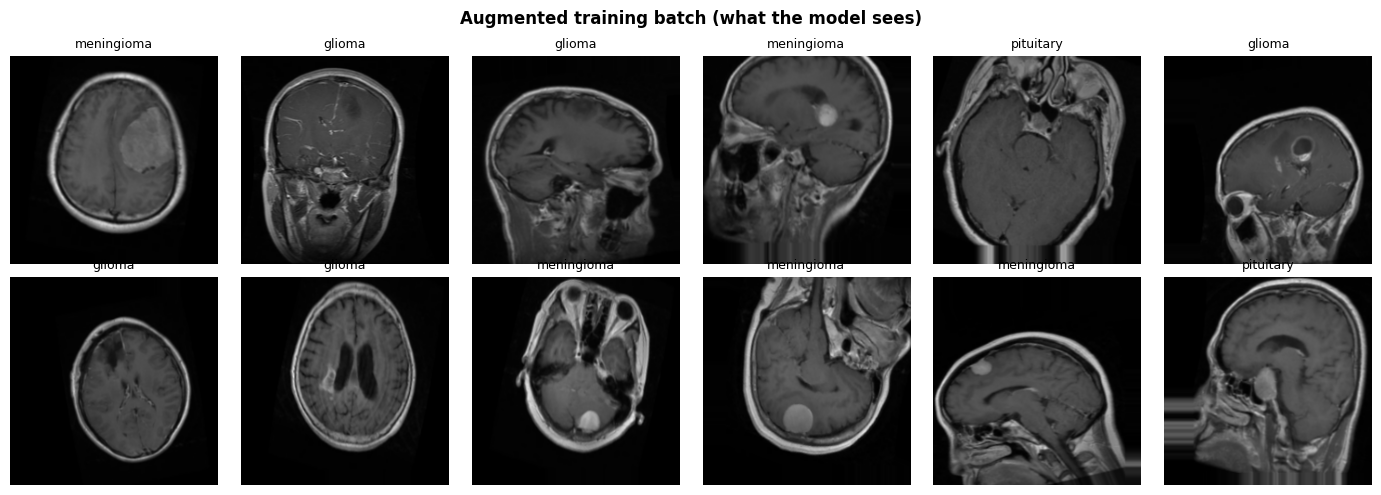

In [7]:
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, img, lab in zip(axes.ravel(), x.numpy(), y.numpy()):
    ax.imshow(img.astype("uint8")); ax.set_title(CLASSES[int(lab.argmax())], fontsize=9); ax.axis("off")
fig.suptitle("Augmented training batch (what the model sees)", fontweight="bold")
plt.tight_layout()
plt.savefig("results/track2_training_batch.png", dpi=130, bbox_inches="tight")
plt.show()

## 2. Model and the BatchNorm fix

**Architecture:** EfficientNetB0 (ImageNet weights, no top) → global average pooling → dropout → Dense(256, ReLU) → dropout → Dense(4, softmax).

**Why Track 1's fine-tuning failed.** Calling `base.trainable = True` makes every BatchNormalization layer in the base update its
moving statistics from our batches. With a small dataset and a small learning rate the statistics get corrupted and accuracy
collapses. A second problem was that `EarlyStopping(restore_best_weights=True)` restores the best epoch *of that `fit()` call*, so it
did not bring back the better weights from phase A.

**What we do instead**
1. The base is called with `training=False`, so BatchNorm runs in inference mode whatever `trainable` says.
2. After unfreezing, every BatchNorm layer is set back to `trainable=False`. Only the convolution/dense kernels of the top *N* layers are
   fine-tuned.
3. The head's weights are saved before fine-tuning. If fine-tuning does **not** improve validation macro-F1, we roll back to them. A
   fine-tune can never silently make the final model worse.

In [8]:
def build_model(dropout=0.3, units=256, n_classes=4):
    """EfficientNetB0 (frozen) + classification head. Returns (model, base)."""
    base = keras.applications.EfficientNetB0(include_top=False, weights=WEIGHTS,
                                             input_shape=info["input_shape"])
    base.trainable = False
    inputs = keras.Input(shape=info["input_shape"])
    h = base(inputs, training=False)                 # BatchNorm stays in inference mode
    h = layers.GlobalAveragePooling2D()(h)
    h = layers.Dropout(dropout)(h)
    h = layers.Dense(units, activation="relu")(h)
    h = layers.Dropout(dropout)(h)
    out = layers.Dense(n_classes, activation="softmax")(h)
    return keras.Model(inputs, out, name="effnet_track2"), base


def set_trainable(base, n_layers):
    """Unfreeze the last `n_layers` of the base, but keep every BatchNorm frozen."""
    base.trainable = True
    for layer in base.layers[:-n_layers]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False


def fit_phase(model, train_ds, val_ds, lr, epochs, tag):
    """One training phase. Always re-compiles (required after changing `trainable`).
    `tag` names this phase's per-epoch backup on Drive: if the session dies mid-phase, running the
    same cell again continues from the last finished epoch (weights, optimiser and epoch counter)."""
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    cbs = [keras.callbacks.BackupAndRestore(os.path.join(BACKUP, tag), save_freq="epoch"),
           keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                         restore_best_weights=True, verbose=1),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2,
                                             min_lr=1e-7, verbose=1)]
    return model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                     class_weight=CLASS_WEIGHTS, callbacks=cbs, verbose=2)


def score(model, ds_split, split):
    """Score with the shared metric code. `split` must be 'val' or 'test' (unshuffled)."""
    probs = model.predict(ds_split, verbose=0)
    y = data.y_true(split)
    return evaluate.compute_metrics(y, probs.argmax(1), CLASSES, y_prob=probs)


m, b = build_model()
print(f"parameters: {m.count_params():,} total | base layers: {len(b.layers)} | "
      f"BatchNorm layers in base: {sum(isinstance(l, layers.BatchNormalization) for l in b.layers)}")
set_trainable(b, 50)
n_bn_train = sum(l.trainable for l in b.layers if isinstance(l, layers.BatchNormalization))
n_train = sum(l.trainable for l in b.layers)
print(f"after set_trainable(50): {n_train} base layers trainable, BatchNorm trainable = {n_bn_train} (must be 0)")
assert n_bn_train == 0
del m, b; gc.collect()

parameters: 4,378,535 total | base layers: 238 | BatchNorm layers in base: 49
after set_trainable(50): 39 base layers trainable, BatchNorm trainable = 0 (must be 0)


24602

## 3. Experiment 1 — head training (backbone frozen)

We first train only the new classification head, which is fast and stable. The grid varies the two settings that matter most here:

* `lr_head` — learning rate of the head (1e-3 vs 3e-4)
* `dropout` — regularisation in the head (0.3 vs 0.5)

Every run uses seed 42, the same data and the same early-stopping rule, so differences come from the settings. Each model's weights are
kept, so Experiment 2 can start from the best head without retraining it.

**Selection metric: validation macro-F1.** The test set is not used.

In [9]:
all_runs = load_json("all_runs", [])           # every finished run so far (empty on a fresh start)

def run_row(name, stage, hp, ft_layers, lr_ft, epochs, v, extra=None):
    row = dict(name=name, stage=stage, lr_head=hp["lr_head"], dropout=hp["dropout"],
               ft_layers=ft_layers, lr_ft=lr_ft, epochs=epochs,
               val_acc=v["accuracy"], val_macro_f1=v["macro_f1"],
               val_tumour_missed=v.get("tumour_missed_rate"))
    row.update(extra or {})
    return row

def finished():
    return {r["name"] for r in all_runs}

for hp in HEAD_GRID:
    name = f"head_lr{hp['lr_head']:g}_do{hp['dropout']:g}"
    if name in finished():
        print(f"[skip] {name} - already finished (saved on Drive)")
        continue
    print(f"\n########## {name}")
    t0 = time.time()
    keras.utils.set_random_seed(SEED)
    model, base = build_model(hp["dropout"])
    h = fit_phase(model, ds["train"], ds["val"], hp["lr_head"], EP_HEAD, tag=name)
    v = score(model, ds["val"], "val")
    save_pickle(f"headweights_{name}", model.get_weights())          # weights first ...
    all_runs.append(run_row(name, "head", hp, 0, None, len(h.history["loss"]), v,
                            dict(minutes=(time.time() - t0) / 60)))
    save_json("all_runs", all_runs)                                   # ... then the row, so a row never exists without its weights
    print(f"-> val acc {v['accuracy']:.4f} | val macro-F1 {v['macro_f1']:.4f} | {(time.time()-t0)/60:.1f} min  [saved]")
    del model, base; gc.collect()

exp1 = pd.DataFrame([r for r in all_runs if r["stage"] == "head"])
exp1.to_csv("results/track2_exp1_head.csv", index=False)
sync_to_drive()
exp1[["name", "epochs", "val_acc", "val_macro_f1", "val_tumour_missed"]].round(4)

[skip] head_lr0.001_do0.3 - already finished (saved on Drive)
[skip] head_lr0.001_do0.5 - already finished (saved on Drive)
[skip] head_lr0.0003_do0.3 - already finished (saved on Drive)
[skip] head_lr0.0003_do0.5 - already finished (saved on Drive)


,name,epochs,val_acc,val_macro_f1,val_tumour_missed
0,head_lr0.001_do0.3,9,0.8884,0.8867,0.0173
1,head_lr0.001_do0.5,15,0.8845,0.8849,0.0149
2,head_lr0.0003_do0.3,15,0.8662,0.8642,0.0149
3,head_lr0.0003_do0.5,13,0.8239,0.8236,0.0186


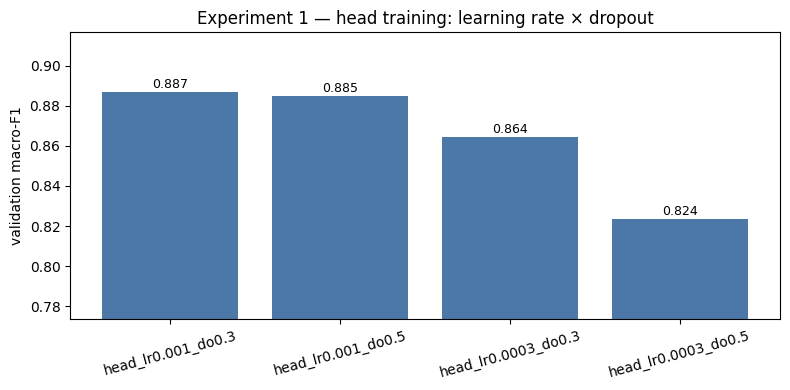

best head configuration: {'name': 'head_lr0.001_do0.3', 'lr_head': 0.001, 'dropout': 0.3} (val macro-F1 0.8867)


In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(exp1["name"], exp1["val_macro_f1"], color="#4C78A8")
ax.set_ylim(max(0, exp1["val_macro_f1"].min() - 0.05), min(1, exp1["val_macro_f1"].max() + 0.03))
for i, v in enumerate(exp1["val_macro_f1"]):
    ax.text(i, v + 0.002, f"{v:.3f}", ha="center", fontsize=9)
ax.set_ylabel("validation macro-F1"); ax.set_title("Experiment 1 — head training: learning rate × dropout")
plt.xticks(rotation=15); plt.tight_layout()
plt.savefig("results/track2_exp1_head.png", dpi=150, bbox_inches="tight"); plt.show()

best_head = exp1.sort_values(["val_macro_f1", "val_acc"], ascending=False).iloc[0]
BEST_HEAD = dict(name=best_head["name"], lr_head=float(best_head["lr_head"]), dropout=float(best_head["dropout"]))
print("best head configuration:", BEST_HEAD, f"(val macro-F1 {best_head['val_macro_f1']:.4f})")

## 4. Experiment 2 — fine-tuning (the part that failed in Track 1)

Starting from the best head of Experiment 1, we unfreeze the top *N* layers of EfficientNetB0 (BatchNorm stays frozen) and train at a
much smaller learning rate. The grid varies:

* `ft_layers` — how many layers at the top of the base are unfrozen (20 / 50 / 100 of the base's layers)
* `lr_ft` — the fine-tuning learning rate (1e-5 vs 3e-5)

Each run is compared with its own starting point. `delta_vs_head` is the change in validation macro-F1 caused by fine-tuning, so a
negative value means fine-tuning hurt. The "head only" run is kept as a row in the final comparison, so we can see whether fine-tuning
earns its extra cost.

In [11]:
head_val = float(best_head["val_macro_f1"])
BEST_HEAD_WEIGHTS = load_pickle(f"headweights_{BEST_HEAD['name']}")
assert BEST_HEAD_WEIGHTS is not None, "saved weights of the best head are missing - set RESET = True and rerun Experiment 1"

EP_FT_EXP2 = 1 if QUICK else 6      # max fine-tuning epochs for Experiment 2 only (the final retrain still uses EP_FT)

for ft in FT_GRID:
    name = f"ft_{BEST_HEAD['name']}_top{ft['ft_layers']}_lr{ft['lr_ft']:g}"
    if name in finished():
        print(f"[skip] {name} - already finished (saved on Drive)")
        continue
    print(f"\n########## {name}")
    t0 = time.time()
    keras.utils.set_random_seed(SEED)
    model, base = build_model(BEST_HEAD["dropout"])
    model.set_weights(BEST_HEAD_WEIGHTS)
    set_trainable(base, ft["ft_layers"])
    n_tr = sum(l.trainable for l in base.layers)
    h = fit_phase(model, ds["train"], ds["val"], ft["lr_ft"], EP_FT_EXP2, tag=name)
    v = score(model, ds["val"], "val")
    all_runs.append(run_row(name, "finetune", BEST_HEAD, ft["ft_layers"], ft["lr_ft"],
                            len(h.history["loss"]), v,
                            dict(trainable_base_layers=n_tr, delta_vs_head=v["macro_f1"] - head_val,
                                 minutes=(time.time() - t0) / 60)))
    save_json("all_runs", all_runs)
    print(f"-> val macro-F1 {v['macro_f1']:.4f}  (head only was {head_val:.4f}, delta {v['macro_f1']-head_val:+.4f})"
          f" | {(time.time()-t0)/60:.1f} min  [saved]")
    del model, base; gc.collect()

exp2 = pd.DataFrame([r for r in all_runs if r["stage"] == "finetune"])
exp2.to_csv("results/track2_exp2_finetune.csv", index=False)
sync_to_drive()
exp2[["name", "ft_layers", "lr_ft", "epochs", "val_acc", "val_macro_f1", "delta_vs_head", "val_tumour_missed"]].round(4)

[skip] ft_head_lr0.001_do0.3_top20_lr1e-05 - already finished (saved on Drive)
[skip] ft_head_lr0.001_do0.3_top20_lr3e-05 - already finished (saved on Drive)
[skip] ft_head_lr0.001_do0.3_top50_lr1e-05 - already finished (saved on Drive)
[skip] ft_head_lr0.001_do0.3_top50_lr3e-05 - already finished (saved on Drive)
[skip] ft_head_lr0.001_do0.3_top100_lr1e-05 - already finished (saved on Drive)
[skip] ft_head_lr0.001_do0.3_top100_lr3e-05 - already finished (saved on Drive)


,name,ft_layers,lr_ft,epochs,val_acc,val_macro_f1,delta_vs_head,val_tumour_missed
0,ft_head_lr0.001_do0.3_top20_lr1e-05,20,0.0,6,0.8797,0.8777,-0.0090,0.0124
1,ft_head_lr0.001_do0.3_top20_lr3e-05,20,0.0,6,0.9163,0.9157,0.0289,0.0099
2,ft_head_lr0.001_do0.3_top50_lr1e-05,50,0.0,6,0.8999,0.8989,0.0122,0.0099
3,ft_head_lr0.001_do0.3_top50_lr3e-05,50,0.0,6,0.9172,0.9149,0.0282,0.0087
4,ft_head_lr0.001_do0.3_top100_lr1e-05,100,0.0,6,0.8980,0.8971,0.0104,0.0062
5,ft_head_lr0.001_do0.3_top100_lr3e-05,100,0.0,6,0.9259,0.9256,0.0389,0.0087


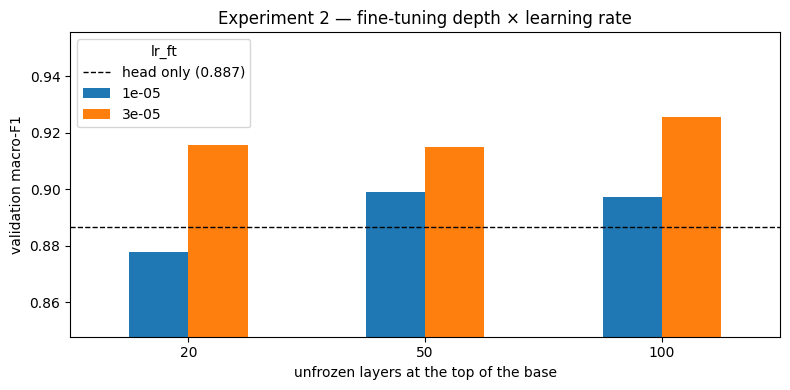

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
pivot = exp2.pivot(index="ft_layers", columns="lr_ft", values="val_macro_f1")
pivot.plot.bar(ax=ax, rot=0)
ax.axhline(head_val, color="k", ls="--", lw=1, label=f"head only ({head_val:.3f})")
lo = min(pivot.min().min(), head_val) - 0.03
ax.set_ylim(max(0, lo), min(1, max(pivot.max().max(), head_val) + 0.03))
ax.set_xlabel("unfrozen layers at the top of the base"); ax.set_ylabel("validation macro-F1")
ax.set_title("Experiment 2 — fine-tuning depth × learning rate"); ax.legend(title="lr_ft")
plt.tight_layout(); plt.savefig("results/track2_exp2_finetune.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Experiment 3 — augmentation ablation (informational)

`neuroscan/data.py` notes that horizontal flip was inherited from the original notebook, and that brain MRI is not left–right
symmetric. We cannot toggle only the flip without changing the shared pipeline, but we can ask the broader question: **does
augmentation help at all** for the best head configuration?

This is an *information-only* experiment. The shared pipeline (with augmentation) stays the contract for every reported model, so this run is
excluded from the final selection.

In [13]:
name = BEST_HEAD["name"] + "_NOAUG"
if name in finished():
    print(f"[skip] {name} - already finished (saved on Drive)")
else:
    ds_noaug = make_ds(augment=False)
    keras.utils.set_random_seed(SEED)
    model, base = build_model(BEST_HEAD["dropout"])
    h = fit_phase(model, ds_noaug["train"], ds_noaug["val"], BEST_HEAD["lr_head"], EP_HEAD, tag=name)
    v = score(model, ds_noaug["val"], "val")
    all_runs.append(run_row(name, "ablation", BEST_HEAD, 0, None, len(h.history["loss"]), v))
    save_json("all_runs", all_runs)
    del model, base, ds_noaug; gc.collect()
noaug_f1 = next(r["val_macro_f1"] for r in all_runs if r["name"] == name)

print(f"with augmentation   : val macro-F1 {head_val:.4f}")
print(f"without augmentation: val macro-F1 {noaug_f1:.4f}   (difference {noaug_f1-head_val:+.4f})")

[skip] head_lr0.001_do0.3_NOAUG - already finished (saved on Drive)
with augmentation   : val macro-F1 0.8867
without augmentation: val macro-F1 0.9602   (difference +0.0735)


## 6. Choosing the final configuration (validation data only)

Every run so far is in one table. The final configuration is the one with the highest **validation macro-F1** among the head and
fine-tuning runs (the ablation row is excluded). If the best row is a head-only run, then the honest conclusion is that fine-tuning did not help
on this data and we say so.

In [14]:
runs = pd.DataFrame(all_runs)
runs.to_csv("results/track2_all_runs.csv", index=False)
sync_to_drive()

cand = runs[runs["stage"].isin(["head", "finetune"])].sort_values(["val_macro_f1", "val_acc"], ascending=False)
best = cand.iloc[0]
FINAL = dict(
    lr_head=float(best["lr_head"]), dropout=float(best["dropout"]),
    ft_layers=int(best["ft_layers"]), lr_ft=None if pd.isna(best["lr_ft"]) else float(best["lr_ft"]),
)
print("FINAL CONFIGURATION (chosen on validation macro-F1):", FINAL)
print(f"validation macro-F1 {best['val_macro_f1']:.4f} | validation accuracy {best['val_acc']:.4f}\n")
runs[["name", "stage", "ft_layers", "lr_ft", "val_acc", "val_macro_f1", "val_tumour_missed"]] \
    .sort_values("val_macro_f1", ascending=False).round(4).reset_index(drop=True)

FINAL CONFIGURATION (chosen on validation macro-F1): {'lr_head': 0.001, 'dropout': 0.3, 'ft_layers': 100, 'lr_ft': 3e-05}
validation macro-F1 0.9256 | validation accuracy 0.9259



,name,stage,ft_layers,lr_ft,val_acc,val_macro_f1,val_tumour_missed
0,head_lr0.001_do0.3_NOAUG,ablation,0,NaN,0.9596,0.9602,0.0050
1,ft_head_lr0.001_do0.3_top100_lr3e-05,finetune,100,0.0,0.9259,0.9256,0.0087
2,ft_head_lr0.001_do0.3_top20_lr3e-05,finetune,20,0.0,0.9163,0.9157,0.0099
3,ft_head_lr0.001_do0.3_top50_lr3e-05,finetune,50,0.0,0.9172,0.9149,0.0087
4,ft_head_lr0.001_do0.3_top50_lr1e-05,finetune,50,0.0,0.8999,0.8989,0.0099
5,ft_head_lr0.001_do0.3_top100_lr1e-05,finetune,100,0.0,0.8980,0.8971,0.0062
6,head_lr0.001_do0.3,head,0,NaN,0.8884,0.8867,0.0173
7,head_lr0.001_do0.5,head,0,NaN,0.8845,0.8849,0.0149
8,ft_head_lr0.001_do0.3_top20_lr1e-05,finetune,20,0.0,0.8797,0.8777,0.0124
9,head_lr0.0003_do0.3,head,0,NaN,0.8662,0.8642,0.0149


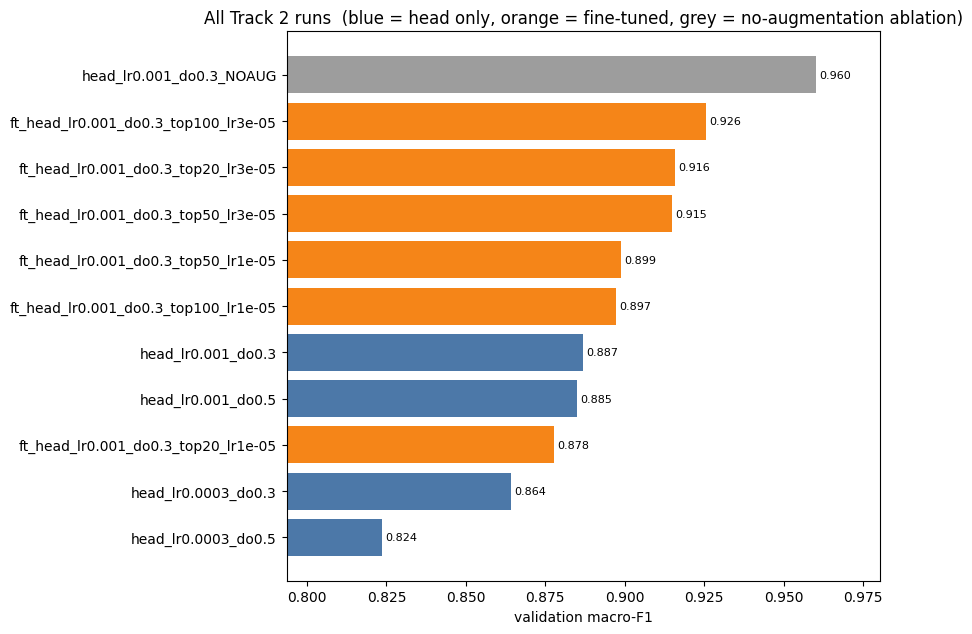

In [15]:
colors = {"head": "#4C78A8", "finetune": "#F58518", "ablation": "#9D9D9D"}
r = runs.sort_values("val_macro_f1")
fig, ax = plt.subplots(figsize=(9, 0.45 * len(r) + 1.5))
ax.barh(r["name"], r["val_macro_f1"], color=[colors[s] for s in r["stage"]])
ax.set_xlim(max(0, r["val_macro_f1"].min() - 0.03), min(1, r["val_macro_f1"].max() + 0.02))
for i, v in enumerate(r["val_macro_f1"]):
    ax.text(v + 0.001, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlabel("validation macro-F1")
ax.set_title("All Track 2 runs  (blue = head only, orange = fine-tuned, grey = no-augmentation ablation)")
plt.tight_layout(); plt.savefig("results/track2_all_runs.png", dpi=150, bbox_inches="tight"); plt.show()

In [16]:
EP_HEAD = 8
EP_FT = 8
FINAL_SEEDS = [42, 7]

## 7. Final model: retrain with three seeds, then evaluate on the test set

One training run can be lucky or unlucky. To judge whether a difference between models is real, we retrain the chosen configuration with
three seeds (the seed changes the weight initialisation of the head, the shuffling and the augmentation).

* **Seed 42** is the project-wide seed. It is saved as `models/effnet_tuned.keras` and its metrics go into the shared comparison table.
* The other seeds are used only to report the spread (mean ± standard deviation).
* The fine-tune is rolled back to the head model if it does not improve validation macro-F1, so a bad fine-tune cannot damage the result.

**This is the first and only place the test set is used.** The test numbers were not used to choose anything above.

In [17]:
def train_final(cfg, seed):
    # Train one final seed - or, if it finished in an earlier session, simply reload it.
    ds_s = make_ds(seed=seed)
    tag = f"final_s{seed}"
    keras.utils.set_random_seed(seed)
    model, base = build_model(cfg["dropout"])

    done = load_pickle(tag + "_final")                       # this seed already finished?
    if done:
        print(f"[skip] seed {seed} - already trained, loading it from Drive")
        model.set_weights(done["weights"])
        return model, done["hists"], ds_s, done["kept"]

    head = load_pickle(tag + "_head")                        # head phase already finished?
    if head:
        print(f"[skip] seed {seed} head phase - loading it from Drive")
        model.set_weights(head["weights"]); hists = [head["hist"]]
    else:
        h = fit_phase(model, ds_s["train"], ds_s["val"], cfg["lr_head"], EP_HEAD, tag=tag + "_head")
        hists = [h.history]
        save_pickle(tag + "_head", dict(weights=model.get_weights(), hist=h.history))
    f1_head = score(model, ds_s["val"], "val")["macro_f1"]

    kept_ft = False
    if cfg["ft_layers"] > 0:
        w_head = model.get_weights()
        set_trainable(base, cfg["ft_layers"])
        h_ft = fit_phase(model, ds_s["train"], ds_s["val"], cfg["lr_ft"], EP_FT, tag=tag + "_ft")
        f1_ft = score(model, ds_s["val"], "val")["macro_f1"]
        if f1_ft >= f1_head:
            hists.append(h_ft.history); kept_ft = True
        else:
            model.set_weights(w_head)          # roll back: the fine-tune made validation worse
            print(f"!! fine-tune rolled back (val macro-F1 {f1_ft:.4f} < head {f1_head:.4f})")
    save_pickle(tag + "_final", dict(weights=model.get_weights(), hists=hists, kept=kept_ft))
    return model, hists, ds_s, kept_ft

seed_rows, final_model, final_hists = [], None, None
for seed in FINAL_SEEDS:
    print(f"\n########## final run, seed {seed}")
    model, hists, ds_s, kept_ft = train_final(FINAL, seed)
    v = score(model, ds_s["val"], "val")
    if seed == SEED:
        # saves results/effnet_tuned_{metrics.json,report.txt,confusion.png}
        t = evaluate.evaluate_model(model, ds_s["test"], CLASSES, name="effnet_tuned", outdir="results")
        model.save("models/effnet_tuned.keras")
        evaluate.plot_history(hists, "results/effnet_tuned_history.png", "EfficientNetB0 (tuned)")
        final_model, final_hists, final_ds = model, hists, ds_s
        sync_to_drive()                                    # the main model is safe on Drive before the other seeds start
    else:
        t = score(model, ds_s["test"], "test")
    seed_rows.append(dict(seed=seed, kept_finetune=kept_ft, val_acc=v["accuracy"], val_macro_f1=v["macro_f1"],
                          test_acc=t["accuracy"], test_macro_f1=t["macro_f1"],
                          test_tumour_missed=t.get("tumour_missed_rate")))
    print(f"seed {seed}: test accuracy {t['accuracy']:.4f} | test macro-F1 {t['macro_f1']:.4f}")
    if seed != SEED:
        del model; gc.collect()

seeds = pd.DataFrame(seed_rows)
seeds.to_csv("results/track2_seeds.csv", index=False)
sync_to_drive()
seeds.round(4)


########## final run, seed 42
[skip] seed 42 - already trained, loading it from Drive
seed 42: test accuracy 0.8826 | test macro-F1 0.8788

########## final run, seed 7
Epoch 5/8
130/130 - 100s - 773ms/step - accuracy: 0.8956 - loss: 0.2760 - val_accuracy: 0.8412 - val_loss: 0.4324 - learning_rate: 0.0010
Epoch 6/8
130/130 - 27s - 205ms/step - accuracy: 0.9030 - loss: 0.2543 - val_accuracy: 0.8470 - val_loss: 0.3921 - learning_rate: 0.0010
Epoch 7/8
130/130 - 29s - 220ms/step - accuracy: 0.8968 - loss: 0.2544 - val_accuracy: 0.8489 - val_loss: 0.3950 - learning_rate: 0.0010
Epoch 8/8
130/130 - 29s - 221ms/step - accuracy: 0.8997 - loss: 0.2507 - val_accuracy: 0.8730 - val_loss: 0.3341 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 8.
Epoch 5/8
130/130 - 114s - 878ms/step - accuracy: 0.8965 - loss: 0.2701 - val_accuracy: 0.9076 - val_loss: 0.2529 - learning_rate: 3.0000e-05
Epoch 6/8
130/130 - 29s - 223ms/step - accuracy: 0.9129 - loss: 0.2325 - val_acc

,seed,kept_finetune,val_acc,val_macro_f1,test_acc,test_macro_f1,test_tumour_missed
0,42,True,0.9355,0.9346,0.8826,0.8788,0.0585
1,7,True,0.9269,0.9249,0.8545,0.8479,0.0704


In [18]:
summary = seeds[["val_acc", "val_macro_f1", "test_acc", "test_macro_f1", "test_tumour_missed"]].agg(["mean", "std"]).T
summary.columns = ["mean", "std"]
print(f"EfficientNetB0 (tuned), {len(seeds)} seed(s):")
print(summary.round(4).to_string())
print(f"\nvalidation -> test gap (macro-F1, mean): {seeds.val_macro_f1.mean() - seeds.test_macro_f1.mean():+.4f}")

EfficientNetB0 (tuned), 2 seed(s):
                      mean     std
val_acc             0.9312  0.0061
val_macro_f1        0.9298  0.0069
test_acc            0.8685  0.0199
test_macro_f1       0.8634  0.0218
test_tumour_missed  0.0645  0.0084

validation -> test gap (macro-F1, mean): +0.0664


effnet_tuned
samples            1567
accuracy           0.8826
balanced accuracy  0.8823
macro F1           0.8788
macro precision    0.8895
macro recall       0.8823

class             prec     rec      f1      n
glioma          0.9284  0.8120  0.8663    383
meningioma      0.9286  0.7222  0.8125    396
notumor         0.8484  0.9948  0.9158    388
pituitary       0.8529  1.0000  0.9206    400

tumours called 'no tumour': 69 (5.85%)



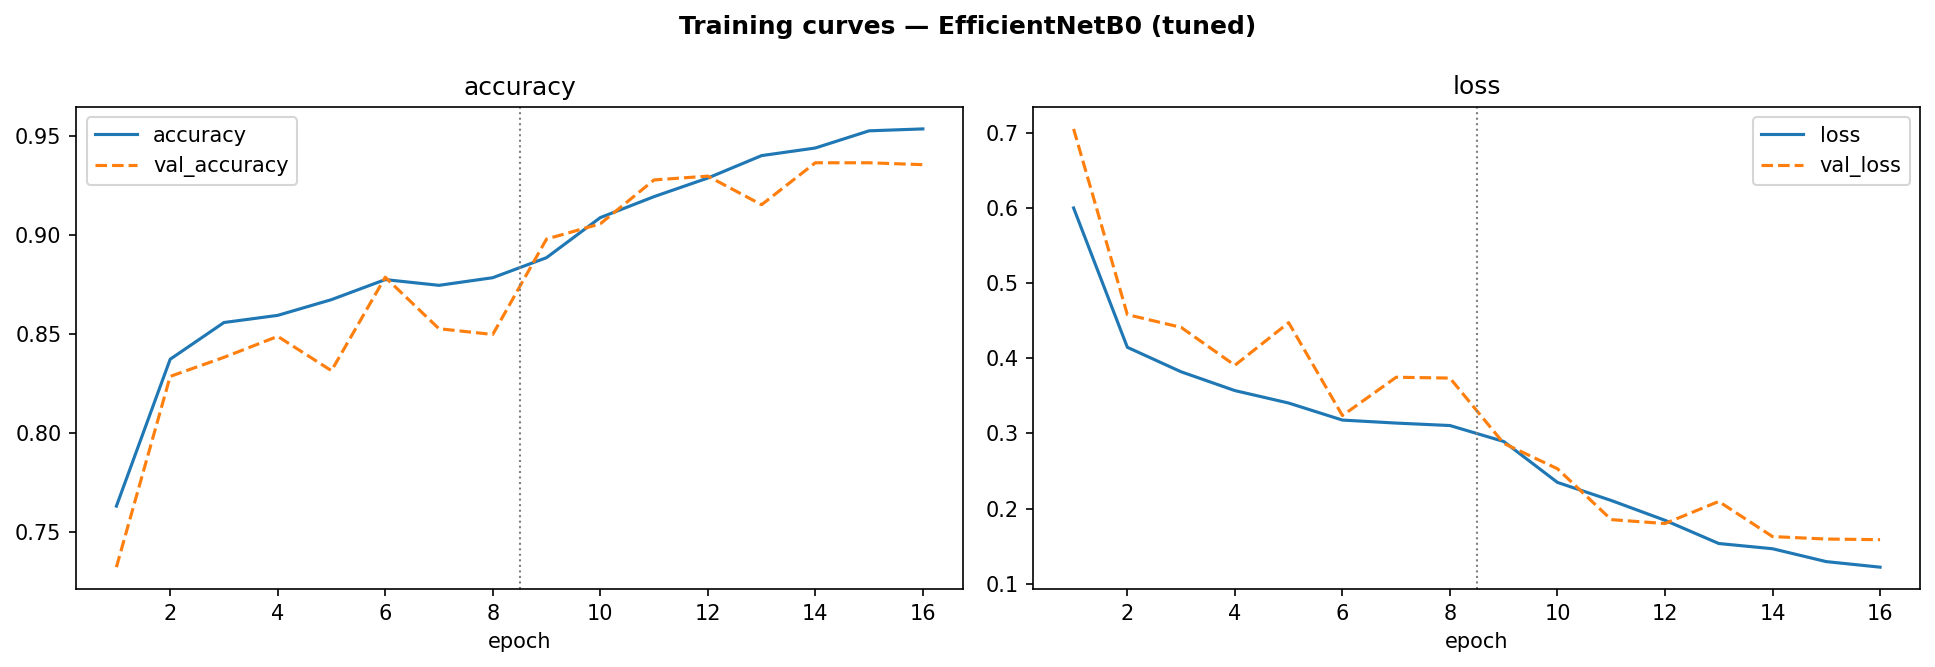

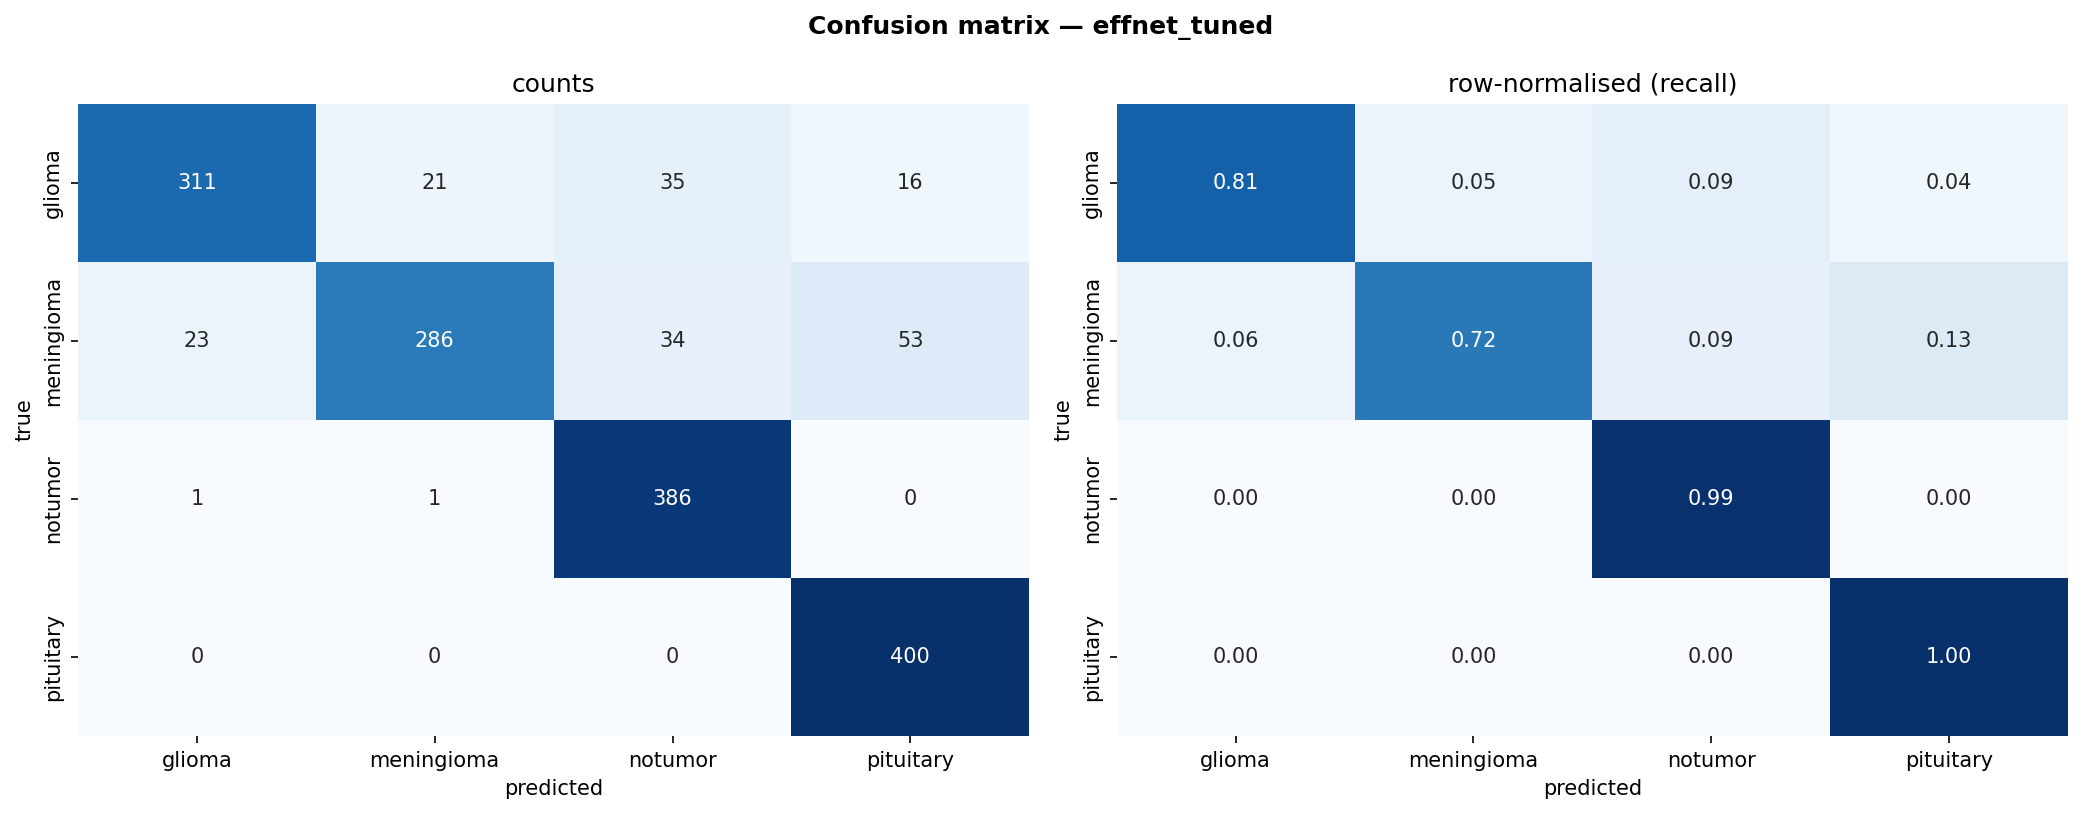

In [19]:
print(open("results/effnet_tuned_report.txt").read())
from IPython.display import Image, display
display(Image("results/effnet_tuned_history.png"))
display(Image("results/effnet_tuned_confusion.png"))

## 8. Comparison with Track 1

All rows use the same clean split, preprocessing, augmentation and metric code. The leaky-pipeline rows from Track 1 are removed on purpose:
**they must never be quoted as a result.** `save=False` means we do not overwrite `results/comparison.*`, which Track 1 owns (writing it from two branches
would cause merge conflicts).

In [20]:
comp = evaluate.comparison_table("results", save=False)
comp = comp[~comp["model"].str.contains("leaky")].reset_index(drop=True)
comp.to_csv("results/track2_comparison.csv", index=False)
with open("results/track2_comparison.md", "w", encoding="utf-8") as fh:
    fh.write(evaluate._markdown(comp))
comp

,model,n,accuracy,balanced_acc,macro_f1,macro_recall,macro_auc,tumour_missed
0,effnet_tuned,1567,0.8826,0.8823,0.8788,0.8823,0.9811,0.0585
1,effnet_clean_best,1567,0.8551,0.8544,0.8500,0.8544,0.9711,0.0560
2,baseline_cnn,1567,0.8060,0.8052,0.7976,0.8052,0.9336,0.1501


In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
c = comp.sort_values("macro_f1")
ax[0].barh(c["model"], c["macro_f1"], color="#4C78A8")
ax[0].set_xlim(c["macro_f1"].min() - 0.05, min(1, c["macro_f1"].max() + 0.03))
ax[0].set_xlabel("test macro-F1"); ax[0].set_title("Test macro-F1")
for i, v in enumerate(c["macro_f1"]): ax[0].text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=9)
if "tumour_missed" in c:
    ax[1].barh(c["model"], c["tumour_missed"] * 100, color="#E45756")
    ax[1].set_xlabel("% of tumours predicted as 'no tumour'"); ax[1].set_title("Missed tumours (lower is better)")
    for i, v in enumerate(c["tumour_missed"] * 100): ax[1].text(v + 0.1, i, f"{v:.1f}%", va="center", fontsize=9)
plt.tight_layout(); plt.savefig("results/track2_model_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

## 9. Error analysis — where does the model fail?

Three questions: (1) which classes get confused with which, (2) is the model more confident when it is right than when it is wrong, and
(3) what do the mistakes look like? The clinically worst error is a tumour predicted as "no tumour".

In [22]:
probs = final_model.predict(final_ds["test"], verbose=0)
y_true = np.array(data.y_true("test"))
y_pred = probs.argmax(1)
conf   = probs.max(1)
wrong  = y_pred != y_true

cm = evaluate.compute_metrics(y_true, y_pred, CLASSES)["confusion_matrix"]
cm = np.array(cm)
pairs = [(CLASSES[i], CLASSES[j], int(cm[i, j])) for i in range(4) for j in range(4) if i != j and cm[i, j] > 0]
pairs = sorted(pairs, key=lambda t: -t[2])
print(f"test errors: {wrong.sum()} of {len(y_true)} ({wrong.mean():.1%})\n")
print("most common confusions (true -> predicted):")
for t, p, n in pairs[:6]:
    print(f"  {t:<11} -> {p:<11} {n:>4}  ({n / cm[CLASSES.index(t)].sum():.1%} of all true {t})")

print(f"\nmean confidence when correct: {conf[~wrong].mean():.3f} | when wrong: {conf[wrong].mean():.3f}")
print(f"errors made with confidence > 0.9: {(wrong & (conf > 0.9)).sum()} of {wrong.sum()}")

test errors: 184 of 1567 (11.7%)

most common confusions (true -> predicted):
  meningioma  -> pituitary     53  (13.4% of all true meningioma)
  glioma      -> notumor       35  (9.1% of all true glioma)
  meningioma  -> notumor       34  (8.6% of all true meningioma)
  meningioma  -> glioma        23  (5.8% of all true meningioma)
  glioma      -> meningioma    21  (5.5% of all true glioma)
  glioma      -> pituitary     16  (4.2% of all true glioma)

mean confidence when correct: 0.947 | when wrong: 0.769
errors made with confidence > 0.9: 60 of 184


In [23]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(conf[~wrong], bins=20, alpha=.7, label="correct", color="#4C78A8")
ax.hist(conf[wrong],  bins=20, alpha=.7, label="wrong",   color="#E45756")
ax.set_xlabel("predicted-class probability"); ax.set_ylabel("test images"); ax.legend()
ax.set_title("Model confidence on the test set")
plt.tight_layout(); plt.savefig("results/track2_confidence.png", dpi=150, bbox_inches="tight"); plt.show()

In [24]:
from PIL import Image as PILImage
rows = data.load_manifest().query("final_split == 'test'").reset_index(drop=True)
idx = np.where(wrong)[0]
idx = idx[np.argsort(-conf[idx])][:12]          # the 12 most confident mistakes
root = data.repo_root()

fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(PILImage.open(os.path.join(root, rows.loc[i, "processed_path"])), cmap="gray")
    ax.set_title(f"true: {CLASSES[y_true[i]]}\npred: {CLASSES[y_pred[i]]} ({conf[i]:.2f})", fontsize=9, color="#B22222")
    ax.axis("off")
fig.suptitle("The 12 most confident mistakes on the test set", fontweight="bold")
plt.tight_layout(); plt.savefig("results/track2_worst_errors.png", dpi=130, bbox_inches="tight"); plt.show()

## 10. Save the artefacts

In [25]:
final_record = dict(
    model="EfficientNetB0 (ImageNet weights), BatchNorm frozen during fine-tuning",
    final_config=FINAL, seeds=FINAL_SEEDS, batch_size=BATCH,
    max_epochs=dict(head=EP_HEAD, finetune=EP_FT), early_stopping_patience=PATIENCE,
    selection_metric="validation macro-F1", tensorflow=tf.__version__,
    test_mean=summary["mean"].round(4).to_dict(), test_std=summary["std"].round(4).to_dict(),
)
with open("results/track2_final_config.json", "w") as fh:
    json.dump(final_record, fh, indent=2, default=str)

size = os.path.getsize("models/effnet_tuned.keras") / 1e6
print(f"models/effnet_tuned.keras : {size:.1f} MB  (GitHub's hard limit is 100 MB)")
print("\nfiles to commit:")
for f in sorted(os.listdir("results")):
    if f.startswith(("track2_", "effnet_tuned_")):
        print("  results/" + f)
print("  models/effnet_tuned.keras")

models/effnet_tuned.keras : 18.4 MB  (GitHub's hard limit is 100 MB)

files to commit:
  results/effnet_tuned_confusion.png
  results/effnet_tuned_history.png
  results/effnet_tuned_metrics.json
  results/effnet_tuned_report.txt
  results/track2_all_runs.csv
  results/track2_all_runs.png
  results/track2_comparison.csv
  results/track2_comparison.md
  results/track2_confidence.png
  results/track2_exp1_head.csv
  results/track2_exp1_head.png
  results/track2_exp2_finetune.csv
  results/track2_exp2_finetune.png
  results/track2_final_config.json
  results/track2_model_comparison.png
  results/track2_seeds.csv
  results/track2_training_batch.png
  results/track2_worst_errors.png
  models/effnet_tuned.keras


In [26]:
sync_to_drive()
print("everything synced to", DRIVE_DIR)
print("\nTo commit: download models/effnet_tuned.keras and the results/track2_* + results/effnet_tuned_* files")
print("from that Drive folder, put them in your local repo, then git add (use -f for the .keras file).")

everything synced to /content/drive/MyDrive/NeuroScan_Phase2_Track2

To commit: download models/effnet_tuned.keras and the results/track2_* + results/effnet_tuned_* files
from that Drive folder, put them in your local repo, then git add (use -f for the .keras file).


## 11. Analysis and conclusions

> **Fill this section in after the real run**, using the numbers printed above. Each point should cite a figure from this notebook.

**1. Which configuration won?** *(Section 6.)* State the final configuration, its validation macro-F1, and the margin over the runner-up. Is the
margin larger than the seed-to-seed standard deviation in Section 7? If not, the choice between those configurations is a tie.

**2. Did fine-tuning help?** *(Experiment 2 and the `delta_vs_head` column.)* Compare the best fine-tuned run with head-only. Say which unfreeze depth and
learning rate worked, and whether any run was rolled back. Link the result to the BatchNorm fix: Track 1's fine-tune lost 16 points; ours should not.

**3. Is augmentation worth it?** *(Experiment 3.)* Report the validation difference. Note that the pipeline contract keeps augmentation on anyway.

**4. How does it compare with Track 1?** *(Section 8.)* Test accuracy and macro-F1 versus the baseline CNN (0.806 / 0.798) and Track 1's EfficientNetB0
(0.855 / 0.850). Is the difference bigger than the standard deviation across seeds? With only 3 seeds we can say "consistent" but not "statistically significant".

**5. Where does it fail?** *(Section 9.)* Name the most confused class pair, the fraction of tumours predicted as "no tumour" (Track 1: 5.6%), and
what the confident mistakes have in common. Mention whether the confidence histogram would let us flag unreliable predictions.

**6. Validation vs test gap.** Validation scores are higher than test scores. Phase 1 found a train/test distribution shift (width, height, contrast and edge
density differ, KS ≈ 0.10–0.12), and the validation split comes from the same folder as the training data. So validation is an
optimistic estimate, and the test figures are the ones to quote.

### Limitations
* **Single hold-out split, no k-fold cross-validation.** The split is fixed by the project contract: re-splitting would risk putting near-duplicates on both sides again,
  which is exactly the leakage Phase 1 removed. Instead we use a small hyperparameter grid and three seeds.
* **Small grid.** Two learning rates, two dropout values, three unfreeze depths and two fine-tuning learning rates. Other settings (image size, optimiser, label smoothing, other
  augmentations) were not explored.
* **Three seeds** give a rough spread, not a confidence interval.
* **Resolution shortcut risk** (Phase 1, Cramér's V = 0.52) is not tested here. Track 3's Grad-CAM is what checks whether the model looks at the tumour.
* **Not a medical device.** Single 2-D slices, one dataset, no clinical validation.

### Possible improvements
Longer fine-tuning with a cosine learning-rate schedule, a larger backbone (EfficientNetB3), test-time augmentation, an ensemble with Track 3's backbone, removing horizontal
flip, and training on the scanner/size-normalised data to reduce the shortcut risk.